# Ungulate Vocalization Valence Prep

Prepare a leakage-aware OpenFARM bioacoustics dataset from the Zenodo release **Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations**.

This is a binary emotional-valence audio benchmark across cow/cattle, sheep, goat, horse, Przewalski's horse, pig, and wild boar contact calls. It is not a pain dataset. The primary OpenFARM split excludes pig-family rows from train/test so models trained here do not leak into SoundWel/PVWB-adjacent pig vocalization evaluation. Pig and wild-boar rows are retained as an explicit eval-only heldout split.


In [1]:
#@title Setup dependencies and imports
!pip -q install datasets huggingface_hub openpyxl scikit-learn soundfile matplotlib seaborn

import hashlib, io, json, os, random, re, zipfile
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import soundfile as sf
from datasets import Audio, Dataset, DatasetDict
from huggingface_hub import HfApi, login
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 180)


In [2]:
#@title Configuration and source verification
UNGULATE_RECORD_ID = "14636641"
ZENODO_API_URL = f"https://zenodo.org/api/records/{UNGULATE_RECORD_ID}"
ZENODO_RECORD_URL = f"https://zenodo.org/records/{UNGULATE_RECORD_ID}"
SOUNDS_ZIP = "SoundsDatabase.zip"
DATA_S1_ZIP = "Data S1.zip"
EXPECTED_MD5 = {
    SOUNDS_ZIP: "46a08a874f8b0b57cc2bbd1d5286bfef",
    DATA_S1_ZIP: "5ec435eadfa87a1e1f1b7282f2538644",
}

def resolve_repo_root() -> Path:
    candidates = []
    if os.environ.get("OPENFARM_REPO_ROOT"):
        candidates.append(Path(os.environ["OPENFARM_REPO_ROOT"]).expanduser())
    cwd = Path.cwd().resolve()
    candidates.extend([cwd, *cwd.parents])
    for candidate in candidates:
        if (candidate / "data" / "ungulate_audio_probe" / "calls_metadata.csv").exists():
            return candidate
        if (candidate / ".prime").exists() and (candidate / "notebooks").exists():
            return candidate
    return cwd


REPO_ROOT = resolve_repo_root()
local_probe_dir = Path(os.environ.get("OPENFARM_UNGULATE_PROBE_DIR", REPO_ROOT / "data" / "ungulate_audio_probe")).expanduser()
if not local_probe_dir.is_absolute():
    local_probe_dir = (REPO_ROOT / local_probe_dir).resolve()

default_work_dir = local_probe_dir if (local_probe_dir / "raw" / SOUNDS_ZIP).exists() else REPO_ROOT / "ungulate_valence_work"
WORK_DIR = Path(os.environ.get("OPENFARM_UNGULATE_WORK_DIR", "/content/openfarm_ungulate_valence" if Path("/content").exists() else str(default_work_dir))).expanduser()
if not WORK_DIR.is_absolute():
    WORK_DIR = (REPO_ROOT / WORK_DIR).resolve()
RAW_DIR = WORK_DIR / "raw"
OUT_DIR = WORK_DIR / "prepared"
AUDIO_DIR = OUT_DIR / "audio"
for d in [RAW_DIR, OUT_DIR, AUDIO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

HF_REPO_ID = "oliveirabruno01/openfarm-ungulate-valence"  #@param {type:"string"}
PUSH_TO_HUB = True  #@param {type:"boolean"}
PRIVATE_REPO = False  #@param {type:"boolean"}
REQUIRE_AUDIO_FOR_PUSH = True  #@param {type:"boolean"}
TEST_SIZE_FALLBACK = 0.20  #@param {type:"number"}
SPLIT_SEED_SEARCH = 2000  #@param {type:"integer"}
VALENCE_CHOICES = ["Negative", "Positive"]


def md5_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.md5()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def download_file(url: str, path: Path, expected_md5: str, expected_size: int) -> Path:
    if path.exists() and path.stat().st_size == expected_size and md5_file(path) == expected_md5:
        print("already verified:", path.name)
        return path
    tmp = path.with_suffix(path.suffix + ".part")
    tmp.unlink(missing_ok=True)
    print("downloading:", path.name)
    with requests.get(url, stream=True, timeout=(60, 600)) as r:
        r.raise_for_status()
        with tmp.open("wb") as f:
            for chunk in r.iter_content(1024 * 1024):
                if chunk:
                    f.write(chunk)
    tmp.replace(path)
    assert path.stat().st_size == expected_size
    assert md5_file(path) == expected_md5
    print("verified:", path.name, expected_size, expected_md5)
    return path

record = requests.get(ZENODO_API_URL, timeout=60).json()
(RAW_DIR / "record.json").write_text(json.dumps(record, indent=2), encoding="utf-8")
print(record["metadata"].get("title"))
print("doi:", record["metadata"].get("doi"))
print("license:", record["metadata"].get("license"))
print("repo root:", REPO_ROOT)
print("probe dir:", local_probe_dir)
print("work dir:", WORK_DIR)

files_by_key = {f["key"]: f for f in record["files"]}
for key in [DATA_S1_ZIP, SOUNDS_ZIP]:
    item = files_by_key[key]
    expected_md5 = item["checksum"].split(":", 1)[1]
    assert expected_md5 == EXPECTED_MD5[key], (key, expected_md5)
    download_file(item["links"]["self"], RAW_DIR / key, expected_md5, int(item["size"]))


Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations
doi: 10.5281/zenodo.14636641
license: {'id': 'cc-by-4.0'}
repo root: /content
probe dir: /content/data/ungulate_audio_probe
work dir: /content/openfarm_ungulate_valence
downloading: Data S1.zip
verified: Data S1.zip 19330 5ec435eadfa87a1e1f1b7282f2538644
downloading: SoundsDatabase.zip
verified: SoundsDatabase.zip 286854334 46a08a874f8b0b57cc2bbd1d5286bfef


In [3]:
#@title Rebuild source metadata, extract opaque audio, and compute summaries
# This cell rebuilds call-level metadata from the verified Zenodo source files.
# A local probe CSV may be compared as an audit artifact, but it is not required.
# The full audio archive is revalidated while rebuilding opaque local audio files.

AUDIO_RE = re.compile(
    r"^(?P<animal_id>[^-]+)-(?P<species>[^-]+)-(?P<context>.+)-"
    r"(?P<valence>Positive|Negative)-(?P<call_index>[^-]+)\.wav$",
    re.I,
)

SOURCE_TO_CONTEXT_CODE = [
    ("full", "separation", "FullSeparation"),
    ("physical", "not", "separation", "PhysicalSeparation"),
    ("visual", "reunion", "VisualReunion"),
    ("physical", "reunion", "PhysicalReunion"),
    ("food frustration", "FoodFrustration"),
    ("short", "isolation", "ShortIsolation"),
    ("food anticipation", "FoodAnticipation"),
    ("separation from one", "IndividualSeparation"),
    ("reunion with one", "IndividualReunion"),
    ("reunion with the whole", "GroupReunion"),
    ("separation from the whole", "GroupSeparation"),
    ("food and toys", "FoodAndToys"),
    ("group separation", "GroupSeparation"),
    ("agonistic", "AgonisticInteractions"),
    ("affiliative", "AffiliativeInteractions"),
    ("pen mate", "Reunion"),
]

CONTEXT_LABELS = {
    "FullSeparation": "Full separation",
    "PhysicalSeparation": "Physical separation",
    "PhysicalReunion": "Physical reunion",
    "VisualReunion": "Visual reunion",
    "FoodFrustration": "Food frustration",
    "ShortIsolation": "Short social isolation",
    "FoodAnticipation": "Food anticipation",
    "IndividualSeparation": "Separation from one group member",
    "IndividualReunion": "Reunion with one group member",
    "GroupReunion": "Reunion with the whole group",
    "GroupSeparation": "Group separation",
    "FoodAndToys": "Food and toys in familiar pen",
    "AgonisticInteractions": "Naturally occurring agonistic interactions",
    "AffiliativeInteractions": "Naturally occurring affiliative interactions",
    "Reunion": "Reunion with pen mate",
}


def norm(value) -> str:
    if pd.isna(value):
        return ""
    return re.sub(r"\s+", " ", str(value).replace("\xa0", " ")).strip()


def slug(value, fallback: str = "unknown") -> str:
    text = norm(value).lower()
    text = re.sub(r"[^a-z0-9]+", "-", text).strip("-")
    return text or fallback


def species_from_source(value) -> str:
    text = norm(value)
    lower = text.lower()
    if "przewalski" in lower:
        return "Przewalski's horse"
    if "wildboar" in lower or "widlboar" in lower or ("wild" in lower and "boar" in lower):
        return "Wild boar"
    if lower in {"cow", "cattle"} or "bos taurus" in lower:
        return "Cow/cattle"
    if lower == "goat":
        return "Goat"
    if lower == "horse":
        return "Horse"
    if lower == "pig":
        return "Pig"
    if lower == "sheep":
        return "Sheep"
    return text


def species_code(species) -> str:
    lower = species_from_source(species).lower()
    if "przewalski" in lower:
        return "PrzewalskiHorse"
    if "wild boar" in lower:
        return "WildBoar"
    if "cow" in lower or "cattle" in lower:
        return "Cow"
    if "goat" in lower:
        return "Goat"
    if lower == "horse":
        return "Horse"
    if "pig" in lower:
        return "Pig"
    if "sheep" in lower:
        return "Sheep"
    return re.sub(r"[^A-Za-z0-9]+", "", lower) or "Unknown"


def context_code(source_context) -> str:
    text = norm(source_context).lower()
    for rule in SOURCE_TO_CONTEXT_CODE:
        *needles, code = rule
        if all(needle in text for needle in needles):
            return code
    return re.sub(r"[^A-Za-z0-9]+", "", norm(source_context)) or "Unknown"


def context_label(code) -> str:
    return CONTEXT_LABELS.get(norm(code), re.sub(r"(?<!^)([A-Z])", r" \1", norm(code)).strip())


def aww_category(valence: str, context: str) -> str:
    if valence == "Positive":
        return "Positive_Welfare"
    return "Negative_Affective"


def read_data_s1(zip_path: Path) -> pd.DataFrame:
    with zipfile.ZipFile(zip_path) as zf:
        with zf.open("Data S1.xlsx") as handle:
            frame = pd.read_excel(handle, sheet_name="Feuil1", header=1, engine="openpyxl")
    frame = frame.dropna(how="all").copy()
    frame.columns = [norm(col) for col in frame.columns]
    for col in ["Species", "Call type", "Reference"]:
        frame[col] = frame[col].replace("", pd.NA).ffill()
    frame["animal_id"] = frame["Animal ID"].map(norm)
    frame["species"] = frame["Species"].map(species_from_source)
    frame["species_code"] = frame["species"].map(species_code)
    frame["call_type"] = frame["Call type"].map(norm)
    frame["valence"] = frame["Valence"].map(norm)
    frame["context"] = frame["Context"].map(norm)
    frame["context_code"] = frame["context"].map(context_code)
    frame["source_reference"] = frame["Reference"].map(norm)
    frame["source_group_n_calls"] = pd.to_numeric(frame["Nb of calls"], errors="coerce").fillna(0).astype(int)
    frame["source_group_id"] = [f"ungulate_group_{i + 1:04d}" for i in range(len(frame))]
    frame["join_key"] = frame.apply(
        lambda row: "|".join([row["animal_id"], row["species_code"], row["context_code"], row["valence"]]),
        axis=1,
    )
    return frame


def audio_members(zip_path: Path) -> list[str]:
    with zipfile.ZipFile(zip_path) as zf:
        return sorted(name for name in zf.namelist() if name.lower().endswith(".wav"))


def parse_audio_member(member: str, idx: int) -> dict:
    filename = Path(member).name
    match = AUDIO_RE.match(filename)
    if not match:
        return {
            "audio_filename": f"ungulate_call_{idx:04d}.wav",
            "source_filename": filename,
            "audio_zip_member": member,
            "filename_parse_ok": False,
            "filename_parse_error": "Filename did not match expected pattern.",
        }
    parts = match.groupdict()
    species = species_from_source(parts["species"])
    ctx_code = norm(parts["context"])
    return {
        "audio_filename": f"ungulate_call_{idx:04d}.wav",
        "source_filename": filename,
        "audio_zip_member": member,
        "filename_parse_ok": True,
        "filename_parse_error": "",
        "animal_id": norm(parts["animal_id"]),
        "species": species,
        "species_raw": norm(parts["species"]),
        "species_code": species_code(species),
        "context": context_label(ctx_code),
        "context_code": ctx_code,
        "valence": norm(parts["valence"]).capitalize(),
        "valence_raw": norm(parts["valence"]),
        "audio_call_index": norm(parts["call_index"]),
    }


def build_call_metadata_from_source(data_s1_zip: Path, sounds_zip: Path) -> pd.DataFrame:
    aggregate = read_data_s1(data_s1_zip)
    members = audio_members(sounds_zip)
    calls = pd.DataFrame([parse_audio_member(member, i + 1) for i, member in enumerate(members)])
    calls["join_key"] = calls.apply(
        lambda row: "|".join([row["animal_id"], row["species_code"], row["context_code"], row["valence"]]),
        axis=1,
    )
    join_cols = ["join_key", "source_group_id", "source_group_n_calls", "call_type", "source_reference"]
    calls = calls.merge(aggregate[join_cols], on="join_key", how="left", validate="many_to_one")
    calls["metadata_join_status"] = calls["source_group_id"].isna().map(
        {True: "filename_only_unmatched_data_s1_group", False: "matched_data_s1_group"}
    )
    species_fallback = aggregate.groupby("species_code")[["call_type", "source_reference"]].first()
    calls["call_type"] = calls["call_type"].fillna(calls["species_code"].map(species_fallback["call_type"]))
    calls["source_reference"] = calls["source_reference"].fillna(calls["species_code"].map(species_fallback["source_reference"]))
    calls = calls.drop(columns=["join_key"])
    calls["n_calls"] = 1
    calls["species_slug"] = calls["species"].map(slug)
    calls["valence_slug"] = calls["valence"].map(slug)
    calls["aww_category"] = calls.apply(lambda row: aww_category(row["valence"], row["context_code"]), axis=1)
    calls["aww_mapping_note"] = "Derived from binary emotional valence/context; source does not label pain, neutral rest, or adversarial false-positive classes."
    calls["is_pig_family"] = calls["species_code"].isin(["Pig", "WildBoar"])
    calls["soundwel_overlap_risk"] = np.select(
        [calls["species_code"].eq("Pig"), calls["species_code"].eq("WildBoar")],
        ["likely", "weak"],
        default="no_overlap",
    )
    calls["soundwel_overlap_note"] = np.select(
        [calls["species_code"].eq("Pig"), calls["species_code"].eq("WildBoar")],
        [
            "Domestic-pig source is the Briefer 2019 pig-valence lineage used near SoundWel/PVWB; exclude from PVWB-adjacent training.",
            "Wild boar is not SoundWel domestic pig data, but is pig-family and shares source-author lineage.",
        ],
        default="No SoundWel/PVWB overlap signal detected.",
    )
    calls["audio_decode_ok"] = True
    calls["audio_error"] = ""
    return calls


print("rebuilding call metadata from verified Zenodo source files")
print("Data S1:", RAW_DIR / DATA_S1_ZIP)
print("Sounds:", RAW_DIR / SOUNDS_ZIP)
metadata_df = build_call_metadata_from_source(RAW_DIR / DATA_S1_ZIP, RAW_DIR / SOUNDS_ZIP)
rebuilt_path = OUT_DIR / "calls_metadata_rebuilt.csv"
metadata_df.to_csv(rebuilt_path, index=False)
print("rebuilt metadata:", rebuilt_path)

# Local probe metadata is useful only as an audit comparison when available.
probe_metadata_path = local_probe_dir / "calls_metadata.csv"
if probe_metadata_path.exists():
    probe_df = pd.read_csv(probe_metadata_path)
    for col in ["valence", "species", "context", "metadata_join_status", "soundwel_overlap_risk", "is_pig_family"]:
        assert Counter(metadata_df[col].astype(str)) == Counter(probe_df[col].astype(str)), col
    assert metadata_df["source_filename"].tolist() == probe_df["source_filename"].tolist()
    assert metadata_df["audio_zip_member"].tolist() == probe_df["audio_zip_member"].tolist()
    print("local probe metadata comparison: passed", probe_metadata_path)
else:
    print("local probe metadata comparison: skipped; source rebuild is canonical for this run")

metadata_df = metadata_df[metadata_df["audio_decode_ok"].fillna(True).astype(bool)].copy().reset_index(drop=True)
required_columns = {"audio_filename", "source_filename", "audio_zip_member", "animal_id", "species", "species_slug", "context", "context_code", "valence", "source_group_id", "call_type", "source_reference", "metadata_join_status", "aww_category", "is_pig_family", "soundwel_overlap_risk"}
assert not (required_columns - set(metadata_df.columns)), required_columns - set(metadata_df.columns)
assert len(metadata_df) == 3181
assert set(metadata_df["valence"]) == set(VALENCE_CHOICES)

FEATURE_COLUMNS = ["duration_sec", "rms_energy", "peak_abs_amplitude", "zero_crossing_rate", "spectral_centroid_hz"]

def sha256_bytes(data: bytes) -> str:
    return hashlib.sha256(data).hexdigest()


def audio_features(data: bytes) -> dict:
    array, sr = sf.read(io.BytesIO(data), dtype="float32", always_2d=True)
    channels = array.shape[1]
    mono = array.mean(axis=1)
    duration = len(mono) / sr if sr else 0.0
    rms = float(np.sqrt(np.mean(mono ** 2))) if len(mono) else 0.0
    peak = float(np.max(np.abs(mono))) if len(mono) else 0.0
    zcr = float(np.mean(np.abs(np.diff(np.signbit(mono))))) if len(mono) > 1 else 0.0
    if len(mono) > 1:
        x = mono
        if len(x) > sr * 20:
            x = x[::max(1, int(len(x) // (sr * 20)))]
        spectrum = np.abs(np.fft.rfft(x))
        freqs = np.fft.rfftfreq(len(x), d=1.0 / sr)
        centroid = float((freqs * spectrum).sum() / spectrum.sum()) if spectrum.sum() > 0 else 0.0
    else:
        centroid = 0.0
    return {"duration_sec": round(duration, 6), "sample_rate_hz": int(sr), "channels": int(channels), "frames": int(len(mono)), "rms_energy": rms, "peak_abs_amplitude": peak, "zero_crossing_rate": zcr, "spectral_centroid_hz": centroid}

feature_rows = []
mapping_rows = []
with zipfile.ZipFile(RAW_DIR / SOUNDS_ZIP) as zf:
    zip_members = set(zf.namelist())
    missing_audio = sorted(set(metadata_df["audio_zip_member"]) - zip_members)
    assert not missing_audio[:5], missing_audio[:5]
    for _, row in metadata_df.iterrows():
        data = zf.read(row["audio_zip_member"])
        audio_hash = sha256_bytes(data)
        opaque_audio_filename = row["audio_filename"]
        out_path = AUDIO_DIR / opaque_audio_filename
        if not out_path.exists() or sha256_bytes(out_path.read_bytes()) != audio_hash:
            out_path.write_bytes(data)
        features = audio_features(data)
        features.update({"audio_sha256": audio_hash, "audio_filename": opaque_audio_filename, "audio": str(out_path)})
        feature_rows.append(features)
        mapping_rows.append({"audio_filename": opaque_audio_filename, "source_filename": row["source_filename"], "audio_zip_member": row["audio_zip_member"], "valence": row["valence"], "species": row["species"], "context": row["context"], "soundwel_overlap_risk": row["soundwel_overlap_risk"]})

features_df = pd.DataFrame(feature_rows)
metadata_df = pd.concat([metadata_df.drop(columns=[c for c in features_df.columns if c in metadata_df.columns], errors="ignore"), features_df], axis=1)
pd.DataFrame(mapping_rows).to_csv(OUT_DIR / "source_mapping_private.csv", index=False)

print("rows:", len(metadata_df))
print("audio files:", len(list(AUDIO_DIR.glob("*.wav"))))
print("valence:", Counter(metadata_df["valence"]))
print("species:", Counter(metadata_df["species"]))
print("soundwel overlap risk:", Counter(metadata_df["soundwel_overlap_risk"]))
print("duration summary:")
display(metadata_df["duration_sec"].describe().round(3))
print("sample rates:", Counter(metadata_df["sample_rate_hz"]))
print("channels:", Counter(metadata_df["channels"]))
print("total minutes:", round(metadata_df["duration_sec"].sum() / 60, 3))


rebuilding call metadata from verified Zenodo source files
Data S1: /content/openfarm_ungulate_valence/raw/Data S1.zip
Sounds: /content/openfarm_ungulate_valence/raw/SoundsDatabase.zip
rebuilt metadata: /content/openfarm_ungulate_valence/prepared/calls_metadata_rebuilt.csv
local probe metadata comparison: skipped; source rebuild is canonical for this run
rows: 3181
audio files: 3181
valence: Counter({'Negative': 2508, 'Positive': 673})
species: Counter({'Cow/cattle': 1254, 'Pig': 564, 'Sheep': 396, 'Goat': 361, 'Horse': 277, 'Wild boar': 262, "Przewalski's horse": 67})
soundwel overlap risk: Counter({'no_overlap': 2355, 'likely': 564, 'weak': 262})
duration summary:


,duration_sec
count,3181.000
mean,1.184
std,0.671
min,0.154
25%,0.654
50%,1.164
75%,1.576
max,5.052


sample rates: Counter({44100: 2779, 48000: 402})
channels: Counter({1: 3181})
total minutes: 62.754


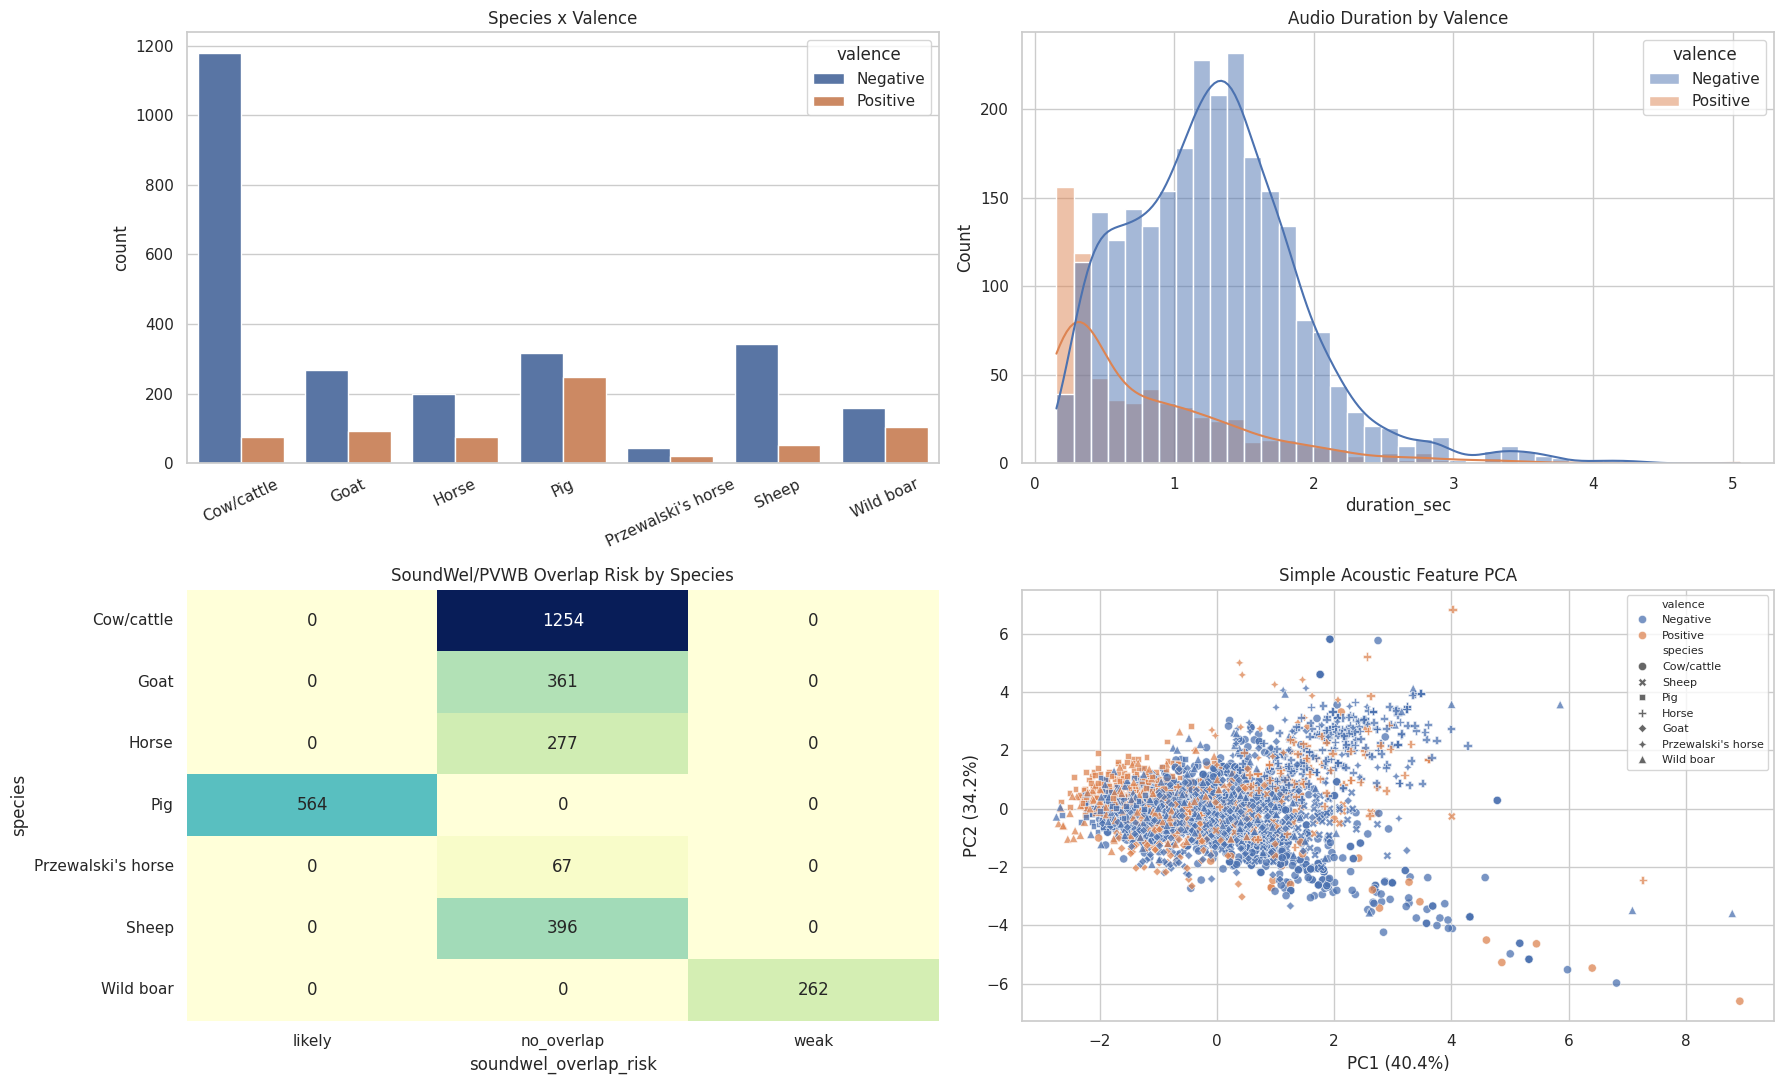

saved: /content/openfarm_ungulate_valence/prepared/ungulate_visual_audit.png
{
  "generated_at": "2026-05-17T15:27:44.575319+00:00",
  "source_url": "https://zenodo.org/records/14636641",
  "doi": "10.5281/zenodo.14636641",
  "license": "cc-by-4.0",
  "source_title": "Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations",
  "rows": 3181,
  "valence_counts": {
    "Negative": 2508,
    "Positive": 673
  },
  "species_counts": {
    "Cow/cattle": 1254,
    "Sheep": 396,
    "Pig": 564,
    "Horse": 277,
    "Goat": 361,
    "Przewalski's horse": 67,
    "Wild boar": 262
  },
  "context_counts": {
    "Full separation": 1078,
    "Physical reunion": 21,
    "Visual reunion": 54,
    "Short social isolation": 846,
    "Physical separation": 101,
    "Reunion with pen mate": 54,
    "Food and toys in familiar pen": 248,
    "Reunion with the whole group": 61,
    "Reunion with one group member": 16,
    "Separation from one group member": 70,
    "Group se

In [4]:
#@title Visual audit
sns.set_theme(style="whitegrid")
source_manifest = {"generated_at": datetime.now(timezone.utc).isoformat(), "source_url": ZENODO_RECORD_URL, "doi": record["metadata"].get("doi"), "license": record["metadata"].get("license", {}).get("id"), "source_title": record["metadata"].get("title"), "rows": int(len(metadata_df)), "valence_counts": dict(Counter(metadata_df["valence"])), "species_counts": dict(Counter(metadata_df["species"])), "context_counts": dict(Counter(metadata_df["context"])), "soundwel_overlap_risk_counts": dict(Counter(metadata_df["soundwel_overlap_risk"])), "duration_sec": {"min": float(metadata_df["duration_sec"].min()), "median": float(metadata_df["duration_sec"].median()), "mean": float(metadata_df["duration_sec"].mean()), "max": float(metadata_df["duration_sec"].max()), "total_minutes": float(metadata_df["duration_sec"].sum() / 60)}, "leakage_policy": "Source filenames encode species/context/valence; public audio filenames are opaque and source filenames stay in source_mapping_private.csv."}
(OUT_DIR / "source_manifest.json").write_text(json.dumps(source_manifest, indent=2, ensure_ascii=False), encoding="utf-8")

fig, axes = plt.subplots(2, 2, figsize=(18, 11))
sns.countplot(data=metadata_df, x="species", hue="valence", order=sorted(metadata_df["species"].unique()), ax=axes[0, 0])
axes[0, 0].set_title("Species x Valence")
axes[0, 0].tick_params(axis="x", rotation=25)
axes[0, 0].set_xlabel("")
sns.histplot(data=metadata_df, x="duration_sec", hue="valence", bins=40, kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Audio Duration by Valence")
risk_table = pd.crosstab(metadata_df["species"], metadata_df["soundwel_overlap_risk"])
sns.heatmap(risk_table, annot=True, fmt="g", cmap="YlGnBu", cbar=False, ax=axes[1, 0])
axes[1, 0].set_title("SoundWel/PVWB Overlap Risk by Species")
feature_matrix = metadata_df[FEATURE_COLUMNS].astype(float)
X_scaled = StandardScaler().fit_transform(feature_matrix)
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X_scaled)
metadata_df["pca1"] = coords[:, 0]
metadata_df["pca2"] = coords[:, 1]
sns.scatterplot(data=metadata_df, x="pca1", y="pca2", hue="valence", style="species", s=35, alpha=0.75, ax=axes[1, 1])
axes[1, 1].set_title("Simple Acoustic Feature PCA")
axes[1, 1].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
axes[1, 1].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
fig_path = OUT_DIR / "ungulate_visual_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)
print(json.dumps(source_manifest, indent=2, ensure_ascii=False))


In [5]:
#@title Build animal-heldout non-pig split and pig-family heldout eval
metadata_df["is_pig_family"] = metadata_df["is_pig_family"].fillna(False).astype(bool)
non_pig_df = metadata_df[~metadata_df["is_pig_family"]].copy().reset_index(drop=True)
pig_family_df = metadata_df[metadata_df["is_pig_family"]].copy().reset_index(drop=True)
non_pig_df["animal_group"] = non_pig_df["species_slug"].astype(str) + "::" + non_pig_df["animal_id"].astype(str)
base_counts = Counter(non_pig_df["valence"])
base_rate = {k: v / len(non_pig_df) for k, v in base_counts.items()}
base_species_rate = {key: n / len(non_pig_df) for key, n in Counter(zip(non_pig_df["species"], non_pig_df["valence"])).items()}

best = None
for seed in range(SEED, SEED + SPLIT_SEED_SEARCH):
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE_FALLBACK, random_state=seed)
    train_idx, test_idx = next(splitter.split(non_pig_df, non_pig_df["valence"], non_pig_df["animal_group"]))
    train_part = non_pig_df.iloc[train_idx]
    test_part = non_pig_df.iloc[test_idx]
    assert set(train_part["animal_group"]).isdisjoint(set(test_part["animal_group"]))
    if len(Counter(test_part["valence"])) < len(VALENCE_CHOICES) or len(set(test_part["species"])) < 5:
        continue
    test_counts = Counter(test_part["valence"])
    test_rate = {k: test_counts.get(k, 0) / len(test_part) for k in base_counts}
    score = sum(abs(test_rate[k] - base_rate[k]) for k in base_counts)
    score += abs(len(test_part) / len(non_pig_df) - TEST_SIZE_FALLBACK) * 0.75
    test_species_counts = Counter(zip(test_part["species"], test_part["valence"]))
    for key, rate in base_species_rate.items():
        score += abs(test_species_counts.get(key, 0) / len(test_part) - rate) * 0.25
    score += (non_pig_df["species"].nunique() - test_part["species"].nunique()) * 0.05
    candidate = (score, seed, train_part.index.tolist(), test_part.index.tolist())
    if best is None or candidate < best:
        best = candidate
assert best is not None
score, split_seed, train_indices, test_indices = best
train_raw_df = non_pig_df.loc[train_indices].copy(); train_raw_df["split"] = "train_raw"
test_raw_df = non_pig_df.loc[test_indices].copy(); test_raw_df["split"] = "test_raw"
pig_family_df["split"] = "pig_family_heldout"

def make_balanced_view(frame: pd.DataFrame, split_name: str, seed: int) -> pd.DataFrame:
    n = int(frame["valence"].value_counts().min())
    pieces = [frame[frame["valence"] == label].sample(n=n, random_state=seed) for label in VALENCE_CHOICES]
    out = pd.concat(pieces).sample(frac=1, random_state=seed).reset_index(drop=True)
    out["split"] = split_name
    return out
train_df = make_balanced_view(train_raw_df, "train", split_seed)
test_df = make_balanced_view(test_raw_df, "test", split_seed)
split_df = pd.concat([train_raw_df, test_raw_df, pig_family_df], ignore_index=True)

print("non-pig rows/groups:", len(non_pig_df), non_pig_df["animal_group"].nunique())
print("pig-family heldout rows:", len(pig_family_df), Counter(pig_family_df["species"]))
print("split seed:", split_seed, "score:", round(score, 4))
print("train_raw rows/groups:", len(train_raw_df), train_raw_df["animal_group"].nunique())
print("test_raw rows/groups:", len(test_raw_df), test_raw_df["animal_group"].nunique())
print("animal-group overlap:", set(train_raw_df["animal_group"]) & set(test_raw_df["animal_group"]))
print("train_raw labels:", Counter(train_raw_df["valence"]))
print("test_raw labels:", Counter(test_raw_df["valence"]))
print("train labels:", Counter(train_df["valence"]))
print("test labels:", Counter(test_df["valence"]))
print("test species:", Counter(test_raw_df["species"]))
display(pd.crosstab(test_raw_df["species"], test_raw_df["valence"]))
for name, frame in {"ungulate_train_raw_metadata.csv": train_raw_df, "ungulate_test_raw_metadata.csv": test_raw_df, "ungulate_train_metadata.csv": train_df, "ungulate_test_metadata.csv": test_df, "ungulate_pig_family_heldout_metadata.csv": pig_family_df}.items():
    frame.to_csv(OUT_DIR / name, index=False)


non-pig rows/groups: 2355 119
pig-family heldout rows: 826 Counter({'Pig': 564, 'Wild boar': 262})
split seed: 626 score: 0.0442
train_raw rows/groups: 1859 95
test_raw rows/groups: 496 24
animal-group overlap: set()
train_raw labels: Counter({'Negative': 1606, 'Positive': 253})
test_raw labels: Counter({'Negative': 428, 'Positive': 68})
train labels: Counter({'Positive': 253, 'Negative': 253})
test labels: Counter({'Negative': 68, 'Positive': 68})
test species: Counter({'Cow/cattle': 272, 'Sheep': 84, 'Horse': 79, 'Goat': 59, "Przewalski's horse": 2})


valence,Negative,Positive
species,,
Cow/cattle,251,21
Goat,43,16
Horse,65,14
Przewalski's horse,0,2
Sheep,69,15


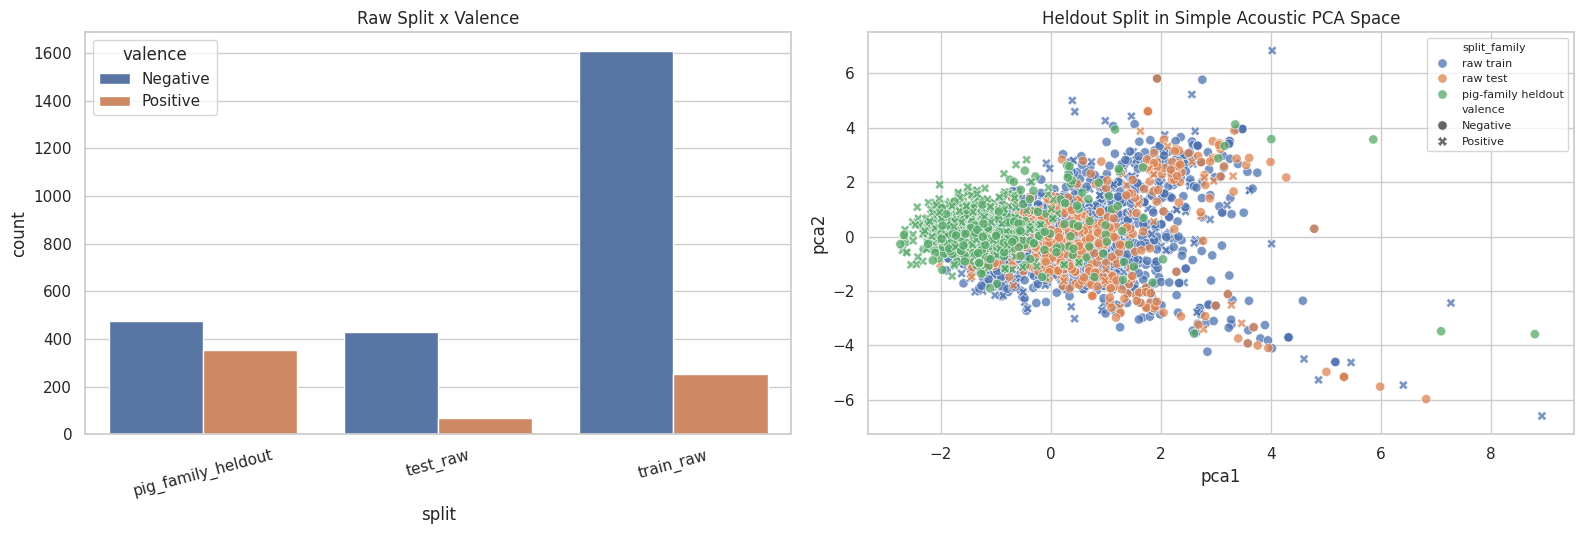

saved: /content/openfarm_ungulate_valence/prepared/ungulate_split_audit.png

Balanced non-pig split: train/test
test label counts: Counter({'Negative': 68, 'Positive': 68})
majority accuracy/balanced_accuracy: 0.5 0.5
logreg accuracy/balanced_accuracy/macro_f1: 0.5662 0.5662 0.566
              precision    recall  f1-score   support

    Negative      0.569     0.544     0.556        68
    Positive      0.563     0.588     0.576        68

    accuracy                          0.566       136
   macro avg      0.566     0.566     0.566       136
weighted avg      0.566     0.566     0.566       136

confusion_matrix labels ['Negative', 'Positive']
[[37 31]
 [28 40]]

Natural non-pig split: train_raw/test_raw
test label counts: Counter({'Negative': 428, 'Positive': 68})
majority accuracy/balanced_accuracy: 0.8629 0.5
logreg accuracy/balanced_accuracy/macro_f1: 0.5988 0.582 0.4994
              precision    recall  f1-score   support

    Negative      0.896     0.605     0.722       4

2129

In [6]:
#@title Split visual audit and shallow acoustic baseline
plot_df = split_df.copy()
plot_df["split_family"] = plot_df["split"].map({"train_raw": "raw train", "test_raw": "raw test", "pig_family_heldout": "pig-family heldout"})
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
split_counts = plot_df.groupby(["split", "valence"]).size().reset_index(name="count")
sns.barplot(data=split_counts, x="split", y="count", hue="valence", ax=axes[0])
axes[0].set_title("Raw Split x Valence")
axes[0].tick_params(axis="x", rotation=15)
sns.scatterplot(data=plot_df, x="pca1", y="pca2", hue="split_family", style="valence", s=45, alpha=0.75, ax=axes[1])
axes[1].set_title("Heldout Split in Simple Acoustic PCA Space")
axes[1].legend(fontsize=8)
plt.tight_layout()
fig_path = OUT_DIR / "ungulate_split_audit.png"
plt.savefig(fig_path, dpi=160, bbox_inches="tight")
plt.show()
print("saved:", fig_path)

LABELS_ORDER = VALENCE_CHOICES

def run_acoustic_baseline(train_frame: pd.DataFrame, test_frame: pd.DataFrame, name: str) -> dict:
    X_train = train_frame[FEATURE_COLUMNS].astype(float).to_numpy()
    X_test = test_frame[FEATURE_COLUMNS].astype(float).to_numpy()
    y_train = train_frame["valence"].tolist()
    y_test = test_frame["valence"].tolist()
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    majority = DummyClassifier(strategy="most_frequent")
    majority.fit(X_train_scaled, y_train)
    majority_pred = majority.predict(X_test_scaled)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)
    clf.fit(X_train_scaled, y_train)
    pred = clf.predict(X_test_scaled)
    print("\n" + "=" * 80)
    print(name)
    print("test label counts:", Counter(y_test))
    print("majority accuracy/balanced_accuracy:", round(accuracy_score(y_test, majority_pred), 4), round(balanced_accuracy_score(y_test, majority_pred), 4))
    print("logreg accuracy/balanced_accuracy/macro_f1:", round(accuracy_score(y_test, pred), 4), round(balanced_accuracy_score(y_test, pred), 4), round(f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"), 4))
    print(classification_report(y_test, pred, labels=LABELS_ORDER, digits=3, zero_division=0))
    print("confusion_matrix labels", LABELS_ORDER)
    print(confusion_matrix(y_test, pred, labels=LABELS_ORDER))
    return {"name": name, "features": FEATURE_COLUMNS, "train_rows": len(train_frame), "test_rows": len(test_frame), "test_label_counts": dict(Counter(y_test)), "majority_accuracy": accuracy_score(y_test, majority_pred), "majority_balanced_accuracy": balanced_accuracy_score(y_test, majority_pred), "acoustic_accuracy": accuracy_score(y_test, pred), "acoustic_balanced_accuracy": balanced_accuracy_score(y_test, pred), "acoustic_macro_f1": f1_score(y_test, pred, labels=LABELS_ORDER, average="macro"), "acoustic_confusion_matrix": confusion_matrix(y_test, pred, labels=LABELS_ORDER).tolist()}

baseline_audit = {
    "balanced_non_pig_split": run_acoustic_baseline(train_df, test_df, "Balanced non-pig split: train/test"),
    "raw_non_pig_split": run_acoustic_baseline(train_raw_df, test_raw_df, "Natural non-pig split: train_raw/test_raw"),
    "pig_family_transfer": run_acoustic_baseline(train_raw_df, pig_family_df, "Pig-family heldout eval from non-pig train_raw"),
}
(OUT_DIR / "baseline_audit.json").write_text(json.dumps(baseline_audit, indent=2, ensure_ascii=False), encoding="utf-8")


In [7]:
#@title Validate leakage guards and build Hugging Face DatasetDict preview
split_frames = {"train": train_df, "test": test_df, "train_raw": train_raw_df, "test_raw": test_raw_df, "pig_family_heldout": pig_family_df}
PUBLIC_FORBIDDEN_COLUMNS = {"source_filename", "audio_zip_member", "source_path", "source_filename_sha256", "task_id"}
PUBLIC_COLUMNS = ["species", "species_raw", "species_code", "species_slug", "animal_id", "context", "context_code", "call_type", "source_reference", "source_group_id", "metadata_join_status", "valence", "aww_category", "aww_mapping_note", "is_pig_family", "soundwel_overlap_risk", "soundwel_overlap_note", "audio_filename", "audio_sha256", "duration_sec", "sample_rate_hz", "channels", "frames", "rms_energy", "peak_abs_amplitude", "zero_crossing_rate", "spectral_centroid_hz"]
consolidated_rows = []
for split_name, frame in split_frames.items():
    for _, row in frame.iterrows():
        assert row["valence"] in VALENCE_CHOICES
        assert str(row["audio_filename"]).startswith("ungulate_call_")
        assert not any(str(row["audio_filename"]).lower().endswith(token) for token in ["positive.wav", "negative.wav"])
        assert Path(row["audio"]).exists(), row["audio"]
        public_row = {col: row.get(col, "") for col in PUBLIC_COLUMNS}
        public_row["audio"] = row["audio"]
        public_row["source_url"] = ZENODO_RECORD_URL
        public_row["source_doi"] = record["metadata"].get("doi") or ""
        public_row["license"] = "cc-by-4.0"
        public_row["split"] = split_name
        consolidated_rows.append(public_row)
hf_df = pd.DataFrame(consolidated_rows)
assert not (PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)), PUBLIC_FORBIDDEN_COLUMNS & set(hf_df.columns)
assert not hf_df[hf_df["split"].isin(["train", "test", "train_raw", "test_raw"])]["is_pig_family"].any()
assert hf_df[hf_df["split"] == "pig_family_heldout"]["is_pig_family"].all()
hf_path = OUT_DIR / "ungulate_hf_dataset.jsonl"
hf_df.to_json(hf_path, orient="records", lines=True, force_ascii=False)
print("dataset total rows:", len(hf_df))
print("split counts:", Counter(hf_df["split"]))
print("wrote:", hf_path)
display(hf_df[["audio_filename", "split", "species", "valence", "context", "soundwel_overlap_risk", "duration_sec"]].head())

split_datasets = {}
for split_name in ["train", "test", "train_raw", "test_raw", "pig_family_heldout"]:
    frame = hf_df[hf_df["split"] == split_name].drop(columns=["split"]).reset_index(drop=True)
    split_datasets[split_name] = Dataset.from_pandas(frame, preserve_index=False)
ds = DatasetDict(split_datasets).cast_column("audio", Audio(sampling_rate=None, decode=False))
print(ds)
preview = ds["train"][0].copy()
preview["audio"] = {k: preview["audio"].get(k) for k in ["path", "bytes"] if k in preview["audio"]}
print(preview)


dataset total rows: 3823
split counts: Counter({'train_raw': 1859, 'pig_family_heldout': 826, 'train': 506, 'test_raw': 496, 'test': 136})
wrote: /content/openfarm_ungulate_valence/prepared/ungulate_hf_dataset.jsonl


,audio_filename,split,species,valence,context,soundwel_overlap_risk,duration_sec
0,ungulate_call_1155.wav,train,Cow/cattle,Positive,Physical reunion,no_overlap,0.827392
1,ungulate_call_0965.wav,train,Sheep,Positive,Reunion with pen mate,no_overlap,1.077333
2,ungulate_call_0230.wav,train,Cow/cattle,Negative,Full separation,no_overlap,2.062766
3,ungulate_call_2259.wav,train,Przewalski's horse,Positive,Food anticipation,no_overlap,0.443492
4,ungulate_call_0902.wav,train,Sheep,Negative,Short social isolation,no_overlap,1.616792


DatasetDict({
    train: Dataset({
        features: ['species', 'species_raw', 'species_code', 'species_slug', 'animal_id', 'context', 'context_code', 'call_type', 'source_reference', 'source_group_id', 'metadata_join_status', 'valence', 'aww_category', 'aww_mapping_note', 'is_pig_family', 'soundwel_overlap_risk', 'soundwel_overlap_note', 'audio_filename', 'audio_sha256', 'duration_sec', 'sample_rate_hz', 'channels', 'frames', 'rms_energy', 'peak_abs_amplitude', 'zero_crossing_rate', 'spectral_centroid_hz', 'audio', 'source_url', 'source_doi', 'license'],
        num_rows: 506
    })
    test: Dataset({
        features: ['species', 'species_raw', 'species_code', 'species_slug', 'animal_id', 'context', 'context_code', 'call_type', 'source_reference', 'source_group_id', 'metadata_join_status', 'valence', 'aww_category', 'aww_mapping_note', 'is_pig_family', 'soundwel_overlap_risk', 'soundwel_overlap_note', 'audio_filename', 'audio_sha256', 'duration_sec', 'sample_rate_hz', 'channels', '

In [8]:
#@title Dataset card scaffold and optional push
train_counts = dict(Counter(train_df["valence"]))
test_counts = dict(Counter(test_df["valence"]))
train_raw_counts = dict(Counter(train_raw_df["valence"]))
test_raw_counts = dict(Counter(test_raw_df["valence"]))
pig_counts = dict(Counter(pig_family_df["valence"]))
all_counts = dict(Counter(metadata_df["valence"]))
species_counts = dict(Counter(metadata_df["species"]))
card = f"""---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Ungulate Vocalization Valence
size_categories:
- 1K<n<10K
tags:
- animal-welfare
- bioacoustics
- ungulates
- audio
- valence
- openfarm
---

# OpenFARM Ungulate Vocalization Valence

This prepared dataset derives from the Zenodo release **Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations**.

Source: {ZENODO_RECORD_URL}
DOI: {record['metadata'].get('doi')}
Source title: {record['metadata'].get('title')}
Source license: CC-BY-4.0
Prepared: {datetime.now(timezone.utc).date().isoformat()}

## Scope

This is an animal bioacoustics benchmark. Given a short ungulate contact-call recording, predict the source-labeled emotional valence: `Negative` or `Positive`.

The labels are emotional valence labels from the source data and associated studies. They are not clinical pain scores, disease labels, or a full welfare diagnosis.

## Source Processing Summary

- Call-level audio rows: {len(metadata_df)}
- Total audio duration: {metadata_df['duration_sec'].sum() / 60:.2f} minutes
- Species counts: {species_counts}
- Valence counts: {all_counts}
- Audio format after preparation: opaque WAV filenames, source filenames withheld from public rows

## Split Policy

The default train/test splits exclude domestic pig and wild boar rows to reduce leakage into SoundWel/PVWB-style pig vocalization evaluation. Those rows are retained in `pig_family_heldout` for explicit transfer or contamination-aware evaluation.

- `train`: balanced non-pig animal-heldout train, counts {train_counts}
- `test`: balanced non-pig animal-heldout test, counts {test_counts}
- `train_raw`: natural-distribution non-pig train, counts {train_raw_counts}
- `test_raw`: natural-distribution non-pig test, counts {test_raw_counts}
- `pig_family_heldout`: eval-only pig-family rows, counts {pig_counts}

The primary split groups by `species_slug::animal_id` and searches for a representative test set across species and valence. Do not use random call-level splits as the headline benchmark.

## Leakage Notes

Source filenames encode species, context, and valence. Prepared audio filenames are opaque (`ungulate_call_XXXX.wav`). The private source mapping is not included in public rows.

Columns such as `context`, `source_reference`, and `animal_id` are useful for audits and specialized ablations but should not be included in the default prompt for valence classification, because context and source-study metadata can be predictive of valence.
"""
card_path = OUT_DIR / "README.md"
card_path.write_text(card, encoding="utf-8")
print(card)
print("wrote:", card_path)

---
license: cc-by-4.0
language:
- en
pretty_name: OpenFARM Ungulate Vocalization Valence
size_categories:
- 1K<n<10K
tags:
- animal-welfare
- bioacoustics
- ungulates
- audio
- valence
- openfarm
---

# OpenFARM Ungulate Vocalization Valence

This prepared dataset derives from the Zenodo release **Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations**.

Source: https://zenodo.org/records/14636641
DOI: 10.5281/zenodo.14636641
Source title: Machine Learning Algorithms Can Predict Emotional Valence Across Ungulate Vocalizations
Source license: CC-BY-4.0
Prepared: 2026-05-17

## Scope

This is an animal bioacoustics benchmark. Given a short ungulate contact-call recording, predict the source-labeled emotional valence: `Negative` or `Positive`.

The labels are emotional valence labels from the source data and associated studies. They are not clinical pain scores, disease labels, or a full welfare diagnosis.

## Source Processing Summary

- Call-level audi

In [10]:
#@title Optional Push to HF
if PUSH_TO_HUB:
    all_audio_available = "audio" in hf_df.columns and hf_df["audio"].map(lambda p: bool(p) and Path(p).exists()).all()
    if REQUIRE_AUDIO_FOR_PUSH and not all_audio_available:
        raise RuntimeError("Audio paths are incomplete; refusing to push audio dataset.")
    token = os.environ.get("HF_TOKEN")
    try:
        from google.colab import userdata
        token = token or userdata.get("HF_TOKEN")
    except Exception:
        pass
    if not token:
        raise RuntimeError("Set HF_TOKEN in the environment or Colab secrets before pushing.")
    login(token=token, add_to_git_credential=False)
    api = HfApi(token=token)
    api.create_repo(HF_REPO_ID, repo_type="dataset", private=PRIVATE_REPO, exist_ok=True)
    ds.push_to_hub(HF_REPO_ID, private=PRIVATE_REPO)
    api.upload_file(path_or_fileobj=str(card_path), path_in_repo="README.md", repo_id=HF_REPO_ID, repo_type="dataset")
    print("pushed:", HF_REPO_ID)
else:
    print("PUSH_TO_HUB is False; dataset preview only.")


Uploading the dataset shards:   0%|          | 0/1 [00:00<?, ? shards/s]

Map:   0%|          | 0/506 [00:00<?, ? examples/s]

Creating parquet from Arrow format:   0%|          | 0/6 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

...

Creating parquet from Arrow format:   0%|          | 0/9 [00:00<?, ?ba/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

                              :  11%|#1        | 4.00MB / 35.4MB            

pushed: oliveirabruno01/openfarm-ungulate-valence


# Review checklist

Before publishing or wiring into `openfarm_bioacustics`:

- confirm Zenodo MD5s and CC-BY-4.0 metadata still match
- inspect a few opaque audio files against `source_mapping_private.csv` locally
- keep `source_filename` and `audio_zip_member` out of public rows and prompts
- keep `context` and `source_reference` out of the default valence prompt unless running an explicit metadata-ablation task
- use `train`/`test` or `train_raw`/`test_raw` as the PVWB-safe default splits
- use `pig_family_heldout` only as an eval-only transfer/contamination-aware split


# Local validation snapshot

This notebook's split and baseline logic was run locally on 2026-05-17 against the full 274 MB `SoundsDatabase.zip` archive.

- Rows: 3,181 decodable mono WAVs, 62.754 total minutes
- Valence counts: `Negative=2508`, `Positive=673`
- Species counts: `Cow/cattle=1254`, `Pig=564`, `Sheep=396`, `Goat=361`, `Horse=277`, `Wild boar=262`, `Przewalski's horse=67`
- PVWB/SoundWel risk flags: `no_overlap=2355`, `likely=564`, `weak=262`
- Primary non-pig split seed: `626`
- `train_raw`: 1,859 rows, 95 animal groups, `Negative=1606`, `Positive=253`
- `test_raw`: 496 rows, 24 animal groups, `Negative=428`, `Positive=68`
- balanced `train`: 506 rows, `Negative=253`, `Positive=253`
- balanced `test`: 136 rows, `Negative=68`, `Positive=68`
- `pig_family_heldout`: 826 rows, `Negative=474`, `Positive=352`
- shallow acoustic logistic baseline balanced accuracy: `0.5662` on balanced non-pig test, `0.5820` on raw non-pig test, `0.5528` on pig-family heldout
